In [23]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import fftconvolve
from scipy.optimize import curve_fit, brentq

In [24]:
def gaussian_kernel(fs, sigma_ms, area=1.0, half_width_sigma=6):
    sigma = sigma_ms / 1000
    kt = np.arange(-half_width_sigma * sigma, half_width_sigma * sigma, 1 / fs)
    h = np.exp(-0.5 * (kt / sigma) ** 2)
    h *= area / (h.sum() / fs)
    return h

def make_signal(params):
    impulses = np.zeros_like(t)
    impulses[stim_idx] = 1.0
    h = gaussian_kernel(fs, **params)
    return fftconvolve(impulses, h, mode="same")

def morlet_transform(x, freqs, fs, n_cycles=5):
    W = np.empty((len(freqs), len(x)), dtype=np.complex128)
    for i, f in enumerate(freqs):
        sigma_t = n_cycles / (2 * np.pi * f)
        wt = np.arange(-4 * sigma_t, 4 * sigma_t, 1 / fs)
        psi = np.exp(2j * np.pi * f * wt) * np.exp(-0.5 * (wt / sigma_t) ** 2)
        psi /= np.sqrt(np.sum(np.abs(psi) ** 2))
        W[i] = fftconvolve(x, np.conj(psi[::-1]), mode="same")
    return W

def epoch_average_power(power, stim_idx, fs, t_pre, t_post):
    rel = np.arange(int(t_pre * fs), int(t_post * fs))
    good = stim_idx[(stim_idx + rel[0] >= 0) & (stim_idx + rel[-1] < power.shape[1])]
    epochs = np.stack([power[:, s + rel] for s in good], axis=0)
    return epochs.mean(axis=0), rel / fs

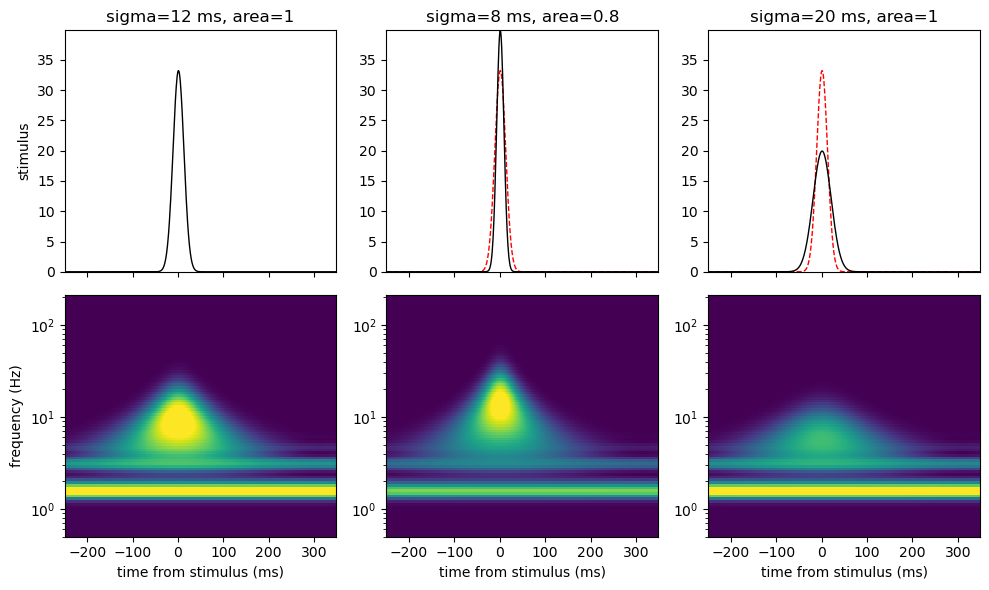

In [25]:
# Params
fs = 1000
dur = 20.0
f0 = 1.6
T = 1 / f0
t_pre, t_post = -0.25, 0.35

freqs = np.geomspace(0.5, 210, 90)
n_cycles = 5

# Condition examples
conditions = {
    'c1': {'sigma_ms': 12, 'area': 1},
    'c2': {'sigma_ms': 8, 'area': 0.8},
    'c3': {'sigma_ms': 20, 'area': 1},
}

cond_labels = {k: f'sigma={p["sigma_ms"]} ms, area={p["area"]}'
               for k, p in conditions.items()}

# Stimulus times
t = np.arange(0, dur, 1 / fs)
stim_times = np.arange(2.0, dur - 2.0, T)
stim_idx = np.round(stim_times * fs).astype(int)

# Run
results = {}
for name, params in conditions.items():
    x = make_signal(params)
    W = morlet_transform(x, freqs, fs, n_cycles)
    P = np.abs(W) ** 2
    Pav, te = epoch_average_power(P, stim_idx, fs, t_pre, t_post)
    rel = np.arange(int(t_pre * fs), int(t_post * fs))
    stim_window = x[stim_idx[0] + rel[0]:stim_idx[0] + rel[-1] + 1]
    results[name] = dict(x=x, P=P, Pav=Pav, stim_window=stim_window)

# Reference stimulus (condition 1)
ref_name = next(iter(results))
ref_window = results[ref_name]["stim_window"]

# Plot
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex='col')

vmax = max(np.percentile(r["Pav"], 99.5) for r in results.values())
vmax *= 0.8

all_stim = np.concatenate([r["stim_window"] for r in results.values()])
ylim_stim = (all_stim.min(), all_stim.max())

for col, (name, r) in enumerate(results.items()):
    ax_top = axes[0, col]
    if col > 0:
        ax_top.plot(te * 1000, ref_window, color='red', linewidth=1, linestyle='--', label='c1')
    ax_top.plot(te * 1000, r["stim_window"], color='black', linewidth=1, label=name)
    ax_top.set_title(cond_labels[name])
    ax_top.set_xlim(te[0] * 1000, te[-1] * 1000)
    ax_top.set_ylim(ylim_stim)
    if col == 0:
        ax_top.set_ylabel('stimulus')

    ax_bottom = axes[1, col]
    ax_bottom.pcolormesh(te * 1000, freqs, r["Pav"], shading="auto", vmin=0, vmax=vmax)
    ax_bottom.set_xlabel("time from stimulus (ms)")
    ax_bottom.set_yscale("log")
    ax_bottom.set_ylim(freqs[0], freqs[-1])

axes[1, 0].set_ylabel("frequency (Hz)")
plt.tight_layout()
plt.show()

# Harmonic amplitudes
for name, params in conditions.items():
    sigma = params["sigma_ms"] / 1000
    area = params["area"]
    #print("\n", cond_labels[name])
    for k in range(1, 8):
        f = k * f0
        H = area * np.exp(-2 * np.pi**2 * sigma**2 * f**2)
        #print(f"{k}f0 = {f:4.1f} Hz: |H| = {H:.4g}")


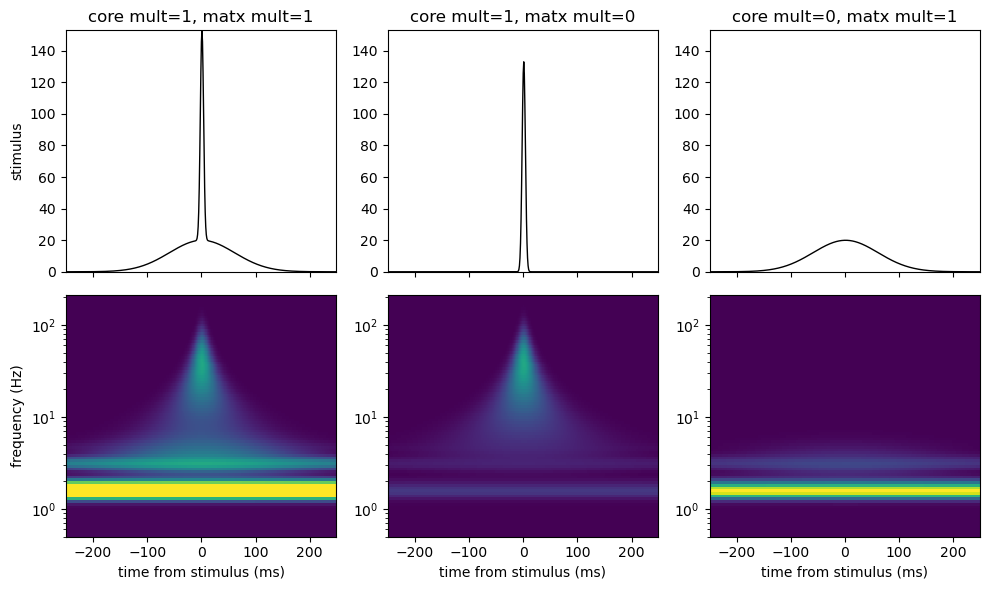

In [26]:
# Params
fs = 1000
dur = 20.0
f0 = 1.6
T = 1 / f0
t_pre, t_post = -0.25, 0.25

freqs = np.geomspace(0.5, 210, 90)
n_cycles = 5

sigma_core = 3
sigma_matx = 60

amp_core = 1
amp_matx = 3

# Condition examples
conditions = {
    'c1': {'core': 1, 'matx': 1},
    'c2': {'core': 1, 'matx': 0},
    'c3': {'core': 0, 'matx': 1},
}

cond_labels = {k: f'core mult={p["core"]}, matx mult={p["matx"]}'
               for k, p in conditions.items()}

# Stimulus times
t = np.arange(0, dur, 1 / fs)
stim_times = np.arange(2.0, dur - 2.0, T)
stim_idx = np.round(stim_times * fs).astype(int)

# Run
results = {}
for name, params in conditions.items():
    # Generate stim trains
    x_core = amp_core * params['core'] * make_signal({'sigma_ms': sigma_core, 'area': 1})
    x_matx = amp_matx * params['matx'] * make_signal({'sigma_ms': sigma_matx, 'area': 1})
    x = x_core + x_matx

    # Spectrogram
    W = morlet_transform(x, freqs, fs, n_cycles)
    P = np.abs(W) ** 2

    # Epoch and average
    Pav, te = epoch_average_power(P, stim_idx, fs, t_pre, t_post)

    # Collect the results
    rel = np.arange(int(t_pre * fs), int(t_post * fs))
    stim_window = x[stim_idx[0] + rel[0]:stim_idx[0] + rel[-1] + 1]
    results[name] = dict(x=x, P=P, Pav=Pav, stim_window=stim_window)

# Reference stimulus (condition 1)
ref_name = next(iter(results))
ref_window = results[ref_name]["stim_window"]

# Plot
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex='col')

vmax = max(np.percentile(r["Pav"], 99.5) for r in results.values())
vmax *= 0.5

all_stim = np.concatenate([r["stim_window"] for r in results.values()])
ylim_stim = (all_stim.min(), all_stim.max())

for col, (name, r) in enumerate(results.items()):
    ax_top = axes[0, col]
    #if col > 0:
    #    ax_top.plot(te * 1000, ref_window, color='red', linewidth=1, linestyle='--', label='c1')
    ax_top.plot(te * 1000, r["stim_window"], color='black', linewidth=1, label=name)
    ax_top.set_title(cond_labels[name])
    ax_top.set_xlim(te[0] * 1000, te[-1] * 1000)
    ax_top.set_ylim(ylim_stim)
    if col == 0:
        ax_top.set_ylabel('stimulus')

    ax_bottom = axes[1, col]
    ax_bottom.pcolormesh(te * 1000, freqs, r["Pav"], shading="auto", vmin=0, vmax=vmax)
    ax_bottom.set_xlabel("time from stimulus (ms)")
    ax_bottom.set_yscale("log")
    ax_bottom.set_ylim(freqs[0], freqs[-1])

axes[1, 0].set_ylabel("frequency (Hz)")
plt.tight_layout()
plt.show()

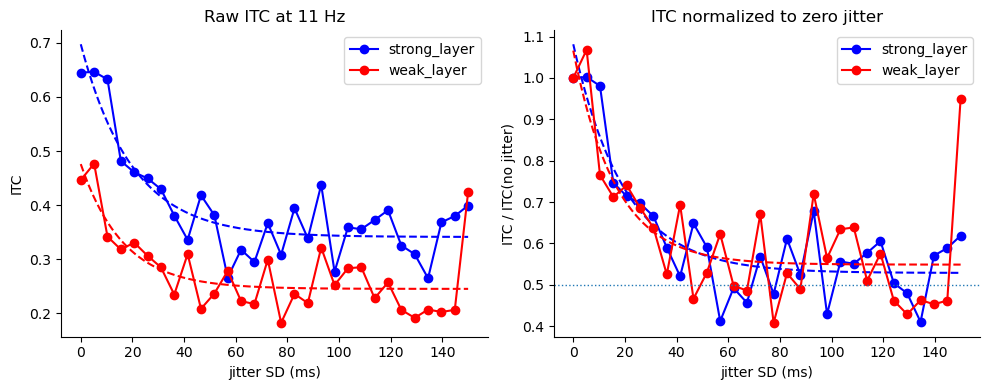

In [27]:
# -----------------------------
# Signal generation
# -----------------------------

def gaussian_kernel(fs, sigma_ms, area=1.0, half_width_sigma=6):
    sigma = sigma_ms / 1000
    kt = np.arange(-half_width_sigma * sigma,
                   half_width_sigma * sigma + 1 / fs,
                   1 / fs)
    h = np.exp(-0.5 * (kt / sigma) ** 2)
    h *= area / (h.sum() / fs)
    return h


def make_jittered_onsets(
    f0,
    dur,
    jitter_sd,
    t0=1.0,
    t1_margin=1.0,
    rng=None,
    min_isi=0.005,
):
    """
    Stimulus onset sequence with SOA ~ Normal(1/f0, jitter_sd).
    Negative/too-small SOAs are resampled.
    """
    rng = np.random.default_rng(rng)
    T = 1 / f0

    times = [t0]
    while True:
        if jitter_sd == 0:
            isi = T
        else:
            isi = rng.normal(T, jitter_sd)
            for _ in range(10000):
                if isi >= min_isi:
                    break
                isi = rng.normal(T, jitter_sd)
            isi = max(isi, min_isi)

        nxt = times[-1] + isi
        if nxt > dur - t1_margin:
            break
        times.append(nxt)

    return np.asarray(times)


def make_train_signal(stim_times, fs, dur, sigma_ms=8, area=1.0):
    t = np.arange(0, dur, 1 / fs)
    impulses = np.zeros_like(t)

    stim_idx = np.round(stim_times * fs).astype(int)
    stim_idx = stim_idx[(stim_idx >= 0) & (stim_idx < len(t))]
    impulses[stim_idx] = 1.0

    h = gaussian_kernel(fs, sigma_ms=sigma_ms, area=area)
    x = fftconvolve(impulses, h, mode="same")
    return x, stim_idx


def simulate_two_layer_dataset(
    *,
    fs=1000,
    dur=8.0,
    f0=11.0,
    jitter_sds=(0.00, 0.04, 0.08, 0.12),
    n_trials=40,
    stim_sigma_ms=8,
    layer_gains=None,
    noise_rms=50.0,
    seed=1,
):
    """
    Returns data[jitter_sd]["signals"][layer] with shape (trial, time),
    and data[jitter_sd]["stim_idx"] as a list of onset-index arrays.
    """
    if layer_gains is None:
        layer_gains = {
            "strong_layer": 1.0,
            "weak_layer": 0.25,
        }

    rng = np.random.default_rng(seed)
    data = {}

    for jitter_sd in jitter_sds:
        signals = {layer: [] for layer in layer_gains}
        stim_idx_trials = []

        for _ in range(n_trials):
            stim_times = make_jittered_onsets(
                f0=f0,
                dur=dur,
                jitter_sd=jitter_sd,
                rng=rng,
                min_isi=0.005,
            )

            clean, stim_idx = make_train_signal(
                stim_times,
                fs=fs,
                dur=dur,
                sigma_ms=stim_sigma_ms,
                area=1.0,
            )

            stim_idx_trials.append(stim_idx)

            for layer, gain in layer_gains.items():
                noise = rng.normal(0, noise_rms, size=clean.shape)
                x = gain * clean + noise
                signals[layer].append(x)

        data[jitter_sd] = {
            "signals": {k: np.stack(v, axis=0) for k, v in signals.items()},
            "stim_idx": stim_idx_trials,
        }

    return data


# -----------------------------
# Morlet phase and ITC
# -----------------------------

def morlet_at_frequency(x, f, fs, n_cycles=5):
    sigma_t = n_cycles / (2 * np.pi * f)
    wt = np.arange(-4 * sigma_t, 4 * sigma_t + 1 / fs, 1 / fs)

    psi = np.exp(2j * np.pi * f * wt) * np.exp(-0.5 * (wt / sigma_t) ** 2)
    psi /= np.sqrt(np.sum(np.abs(psi) ** 2))

    return fftconvolve(x, np.conj(psi[::-1]), mode="same")


def rayleigh_p_from_R(R, n):
    """
    Rayleigh test approximation for non-uniform circular phase distribution.
    R is resultant length, n is number of phase samples.
    """
    z = n * R**2

    if n < 50:
        p = np.exp(np.sqrt(1 + 4*n + 4*(n*n - z*z)) - (1 + 2*n))
    else:
        p = np.exp(-z) * (
            1
            + (2*z - z*z) / (4*n)
            - (24*z - 132*z*z + 76*z**3 - 9*z**4) / (288*n*n)
        )

    return float(np.clip(p, 0, 1))


def rayleigh_p(phases):
    phases = np.asarray(phases)
    if len(phases) < 2:
        return np.nan
    R = np.abs(np.mean(np.exp(1j * phases)))
    return rayleigh_p_from_R(R, len(phases))


def rayleigh_rcrit(n, alpha=0.05):
    """
    ITC threshold corresponding approximately to Rayleigh p=alpha.
    Undefined for fewer than 2 phase samples.
    """
    if n < 2:
        return np.nan
    return brentq(lambda R: rayleigh_p_from_R(R, n) - alpha, 0, 1 - 1e-12)


def fdr_bh(pvals, alpha=0.05):
    p = np.asarray(pvals, dtype=float)
    shape = p.shape
    flat = p.ravel()

    valid = np.isfinite(flat)
    sig = np.zeros(len(flat), dtype=bool)
    if not np.any(valid):
        return sig.reshape(shape)

    valid_idx = np.where(valid)[0]
    ranked_idx = valid_idx[np.argsort(flat[valid_idx])]
    ranked = flat[ranked_idx]
    m = len(ranked)

    passed = ranked <= alpha * np.arange(1, m + 1) / m
    if np.any(passed):
        k = np.max(np.where(passed)[0])
        sig[ranked_idx[:k + 1]] = True

    return sig.reshape(shape)


def calc_itc_for_dataset(
    data,
    *,
    fs,
    f0,
    n_cycles=5,
    sample_mode="one_per_trial",
    alpha=0.05,
):
    """
    sample_mode:
      "one_per_trial" - take the middle valid stimulus onset from each trial.
                        This keeps n ~ number of trials, closer to a strict
                        across-trial ITC estimate.
      "all_events"    - pool all stimulus onsets across trials. This gives
                        smoother ITC but can make significance trivial.
    """
    rows = []

    edge = int(np.ceil(4 * (n_cycles / (2 * np.pi * f0)) * fs))

    for jitter_sd, cond in data.items():
        stim_idx_trials = cond["stim_idx"]

        for layer, X in cond["signals"].items():
            phases = []

            for x, stim_idx in zip(X, stim_idx_trials):
                W = morlet_at_frequency(x, f0, fs, n_cycles=n_cycles)

                valid = stim_idx[
                    (stim_idx >= edge) &
                    (stim_idx < len(x) - edge)
                ]

                if len(valid) == 0:
                    continue

                if sample_mode == "one_per_trial":
                    valid = np.asarray([valid[len(valid) // 2]])
                elif sample_mode == "all_events":
                    pass
                else:
                    raise ValueError("sample_mode must be 'one_per_trial' or 'all_events'")

                phases.append(np.angle(W[valid]))

            if len(phases) == 0:
                rows.append({
                    "layer": layer,
                    "jitter_sd": jitter_sd,
                    "ITC": np.nan,
                    "n_phase_samples": 0,
                    "p_rayleigh": np.nan,
                    "Rcrit_p05": np.nan,
                })
                continue

            phases = np.concatenate(phases)
            n_phase_samples = len(phases)
            ITC = np.abs(np.mean(np.exp(1j * phases)))

            rows.append({
                "layer": layer,
                "jitter_sd": jitter_sd,
                "ITC": ITC,
                "n_phase_samples": n_phase_samples,
                "p_rayleigh": rayleigh_p(phases),
                "Rcrit_p05": rayleigh_rcrit(n_phase_samples, alpha=alpha),
            })

    df = pd.DataFrame(rows).sort_values(["layer", "jitter_sd"]).reset_index(drop=True)

    # FDR across all layer x jitter tests in this toy example.
    df["significant_fdr"] = fdr_bh(df["p_rayleigh"].to_numpy(), alpha=alpha)

    # Normalize to zero-jitter condition within each layer.
    df["ITC_norm"] = df.groupby("layer")["ITC"].transform(lambda y: y / y.iloc[0])

    return df


# -----------------------------
# Fits and tolerance estimates
# -----------------------------

def exp_decay(x, floor, amp, tau):
    return floor + amp * np.exp(-x / tau)


def fit_exp_decay(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    floor0 = max(0, 0.8 * np.nanmin(y))
    amp0 = max(1e-6, y[0] - floor0)
    tau0 = 0.05

    try:
        popt, _ = curve_fit(
            exp_decay,
            x,
            y,
            p0=(floor0, amp0, tau0),
            bounds=([0, 0, 1e-4], [1, 2, 10]),
            maxfev=10000,
        )
    except RuntimeError:
        popt = np.array([np.nan, np.nan, np.nan])

    return popt


def crossing_x_for_exp_decay(params, ycrit):
    floor, amp, tau = params

    if not np.all(np.isfinite(params)) or amp <= 0 or tau <= 0:
        return np.nan

    # Curve starts below criterion.
    if floor + amp < ycrit:
        return 0.0

    # Curve never falls below criterion.
    if floor >= ycrit:
        return np.inf

    return float(-tau * np.log((ycrit - floor) / amp))


def summarize_jitter_tolerance(df):
    rows = []

    for layer, g in df.groupby("layer"):
        g = g.sort_values("jitter_sd")

        raw_params = fit_exp_decay(g["jitter_sd"], g["ITC"])
        norm_params = fit_exp_decay(g["jitter_sd"], g["ITC_norm"])

        # Discrete tolerance: largest tested jitter with significant ITC.
        sig_jitters = g.loc[g["significant_fdr"], "jitter_sd"]
        discrete_tol = float(sig_jitters.max()) if len(sig_jitters) else np.nan

        # Fitted tolerance: crossing of raw-ITC fit with Rayleigh p=0.05 threshold.
        rcrit_values = g["Rcrit_p05"].dropna()
        rcrit = float(rcrit_values.median()) if len(rcrit_values) else np.nan
        fitted_tol = crossing_x_for_exp_decay(raw_params, rcrit)

        # 50% normalized drop, analogous to the dotted-line visualization.
        j50 = crossing_x_for_exp_decay(norm_params, 0.5)

        rows.append({
            "layer": layer,
            "raw_floor": raw_params[0],
            "raw_amp": raw_params[1],
            "raw_tau": raw_params[2],
            "norm_floor": norm_params[0],
            "norm_amp": norm_params[1],
            "norm_tau": norm_params[2],
            "jitter_tolerance_discrete": discrete_tol,
            "jitter_tolerance_fit": fitted_tol,
            "j50_norm_fit": j50,
        })

    return pd.DataFrame(rows)


# -----------------------------
# Run demo
# -----------------------------

fs = 500
f0 = 11.0          # fixed repetition rate; change to 1.6 or 6 if needed
dur = 8.0

data = simulate_two_layer_dataset(
    fs=fs,
    dur=dur,
    f0=f0,
    jitter_sds=np.linspace(0, 0.15, 30),
    n_trials=200,
    stim_sigma_ms=15,
    layer_gains={
        "strong_layer": 0.6,
        "weak_layer": 0.4,
    },
    noise_rms=50.0,
    seed=1,
)

df = calc_itc_for_dataset(
    data,
    fs=fs,
    f0=f0,
    n_cycles=5,
    sample_mode="one_per_trial",   # start here
    alpha=0.05,
)

summary = summarize_jitter_tolerance(df)

# -----------------------------
# Plot
# -----------------------------

jgrid = np.linspace(0, df["jitter_sd"].max(), 200)
colors = ['b', 'r', 'g']

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)


for n, (layer, g) in enumerate(df.groupby("layer")):
    g = g.sort_values("jitter_sd")

    raw_params = fit_exp_decay(g["jitter_sd"], g["ITC"])
    norm_params = fit_exp_decay(g["jitter_sd"], g["ITC_norm"])

    col = colors[n]
    axes[0].plot(g["jitter_sd"] * 1000, g["ITC"], f'{col}o-', label=layer)
    axes[0].plot(jgrid * 1000, exp_decay(jgrid, *raw_params), f'{col}--')

    axes[1].plot(g["jitter_sd"] * 1000, g["ITC_norm"], f'{col}o-', label=layer)
    axes[1].plot(jgrid * 1000, exp_decay(jgrid, *norm_params), f'{col}--')

axes[0].set_title(f"Raw ITC at {f0:g} Hz")
axes[0].set_xlabel("jitter SD (ms)")
axes[0].set_ylabel("ITC")

axes[1].set_title("ITC normalized to zero jitter")
axes[1].set_xlabel("jitter SD (ms)")
axes[1].set_ylabel("ITC / ITC(no jitter)")
axes[1].axhline(0.5, linestyle=":", linewidth=1)

for ax in axes:
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

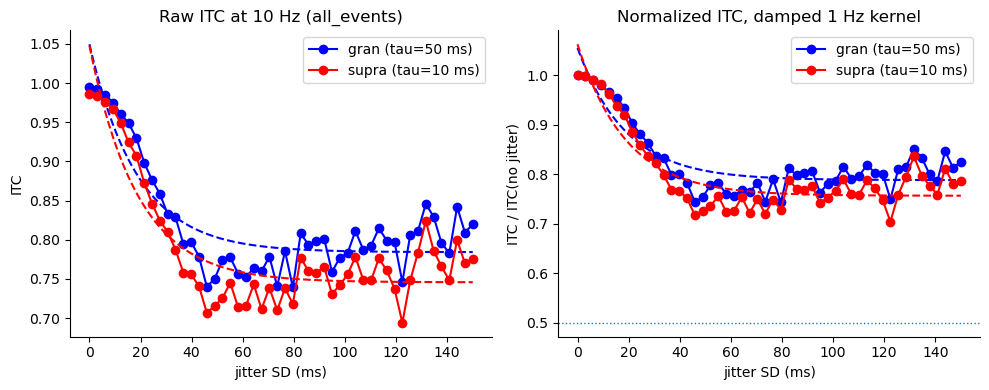

In [ ]:
# -----------------------------
# Jitter analysis with decaying-oscillation stimuli
# -----------------------------

def decaying_osc_kernel(fs, osc_freq_hz, tau_decay, area=1.0, n_tau=6):
    tau = tau_decay / 1000
    kt = np.arange(0, n_tau * tau + 1 / fs, 1 / fs)
    h = np.exp(-kt / tau) * np.cos(2 * np.pi * osc_freq_hz * kt)
    h *= area / np.max(np.abs(h))
    return h


def make_train_signal_osc(stim_times, fs, dur, osc_freq_hz=40, tau_decay=30, area=1.0):
    t = np.arange(0, dur, 1 / fs)
    impulses = np.zeros_like(t)

    stim_idx = np.round(stim_times * fs).astype(int)
    stim_idx = stim_idx[(stim_idx >= 0) & (stim_idx < len(t))]
    impulses[stim_idx] = 1.0

    h = decaying_osc_kernel(
        fs,
        osc_freq_hz=osc_freq_hz,
        tau_decay=tau_decay,
        area=area,
    )
    x = fftconvolve(impulses, h, mode="full")[:len(t)]
    return x, stim_idx


def simulate_two_layer_dataset_osc(
    *,
    fs=1000,
    dur=8.0,
    f0=11.0,
    jitter_sds=(0.00, 0.04, 0.08, 0.12),
    n_trials=40,
    osc_freq_hz=40,
    layer_params=None,
    noise_rms=50.0,
    seed=1,
):
    if layer_params is None:
        layer_params = {
            "strong_layer": {"gain": 1.0, "tau_decay": 30},
            "weak_layer": {"gain": 0.25, "tau_decay": 60},
        }

    rng = np.random.default_rng(seed)
    data_osc = {}

    for jitter_sd in jitter_sds:
        signals = {layer: [] for layer in layer_params}
        stim_idx_trials = []

        for _ in range(n_trials):
            stim_times = make_jittered_onsets(
                f0=f0,
                dur=dur,
                jitter_sd=jitter_sd,
                rng=rng,
                min_isi=0.005,
            )

            stim_idx_ref = None
            for layer, params in layer_params.items():
                clean, stim_idx = make_train_signal_osc(
                    stim_times,
                    fs=fs,
                    dur=dur,
                    osc_freq_hz=osc_freq_hz,
                    tau_decay=params["tau_decay"],
                    area=1.0,
                )
                if stim_idx_ref is None:
                    stim_idx_ref = stim_idx

                noise = rng.normal(0, noise_rms, size=clean.shape)
                x = params["gain"] * clean + noise
                signals[layer].append(x)

            stim_idx_trials.append(stim_idx_ref)

        data_osc[jitter_sd] = {
            "signals": {k: np.stack(v, axis=0) for k, v in signals.items()},
            "stim_idx": stim_idx_trials,
        }

    return data_osc


# -----------------------------
# Run demo
# -----------------------------

fs = 500
dur = 8.0
f0 = 10
sample_mode = "all_events"

osc_freq_hz = 1

layer_params = {
    'supra': {'gain': 1, 'tau_decay': 10},
    'gran': {'gain': 1, 'tau_decay': 50},
}

data_osc = simulate_two_layer_dataset_osc(
    fs=fs,
    dur=dur,
    f0=f0,
    jitter_sds=np.linspace(0, 0.15, 50),
    n_trials=10,
    osc_freq_hz=osc_freq_hz,
    layer_params=layer_params,
    noise_rms=0.25,
    seed=1,
)

df_osc = calc_itc_for_dataset(
    data_osc,
    fs=fs,
    f0=f0,
    n_cycles=5,
    sample_mode=sample_mode,
    alpha=0.05,
)

summary_osc = summarize_jitter_tolerance(df_osc)
summary_osc

# -----------------------------
# Plot
# -----------------------------

jgrid = np.linspace(0, df_osc["jitter_sd"].max(), 200)
colors = ['b', 'r', 'g']
show_fits = bool((df_osc["n_phase_samples"] >= 2).all())
line_fmt = 'o-' if show_fits else 'o'

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True)

for n, (layer, g) in enumerate(df_osc.groupby("layer")):
    g = g.sort_values("jitter_sd")

    raw_params = fit_exp_decay(g["jitter_sd"], g["ITC"])
    norm_params = fit_exp_decay(g["jitter_sd"], g["ITC_norm"])

    col = colors[n]
    tau_decay = layer_params[layer]["tau_decay"]
    axes[0].plot(g["jitter_sd"] * 1000, g["ITC"], f'{col}{line_fmt}', label=f'{layer} (tau={tau_decay} ms)')
    if show_fits:
        axes[0].plot(jgrid * 1000, exp_decay(jgrid, *raw_params), f'{col}--')

    axes[1].plot(g["jitter_sd"] * 1000, g["ITC_norm"], f'{col}{line_fmt}', label=f'{layer} (tau={tau_decay} ms)')
    if show_fits:
        axes[1].plot(jgrid * 1000, exp_decay(jgrid, *norm_params), f'{col}--')

axes[0].set_title(f"Raw ITC at {f0:g} Hz ({sample_mode})")
axes[0].set_xlabel("jitter SD (ms)")
axes[0].set_ylabel("ITC")

axes[1].set_title(f"Normalized ITC")
axes[1].set_xlabel("jitter SD (ms)")
axes[1].set_ylabel("ITC / ITC(no jitter)")
if show_fits:
    axes[1].axhline(0.5, linestyle=":", linewidth=1)
else:
    axes[1].set_ylim(0.95, 1.05)

for ax in axes:
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

30


30


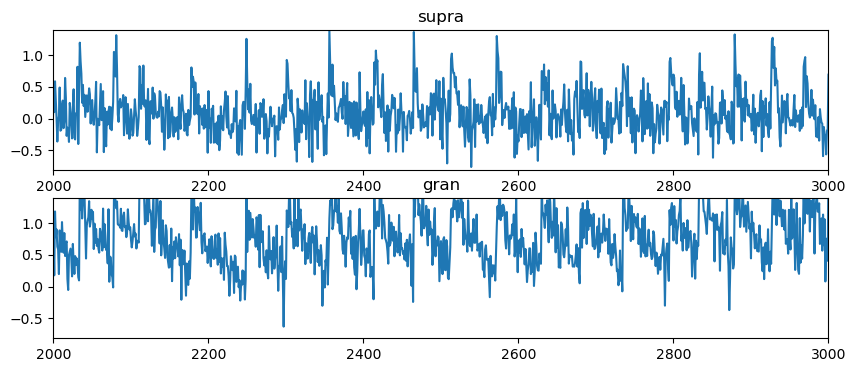

In [76]:
n = 10

k = list(data_osc.keys())[n]
d = data_osc[k]
print(int(k * 1000))

x = {}
for l in d['signals']:
    x[l] = d['signals'][l][0, :]

plt.figure(figsize=(10, 4))

for n, (l, x_) in enumerate(x.items()):
    plt.subplot(len(x), 1, n + 1)
    plt.plot(x_)
    plt.title(l)
    plt.xlim(2000, 3000)
    plt.ylim(x['supra'].min(), x['supra'].max())
plt.show()


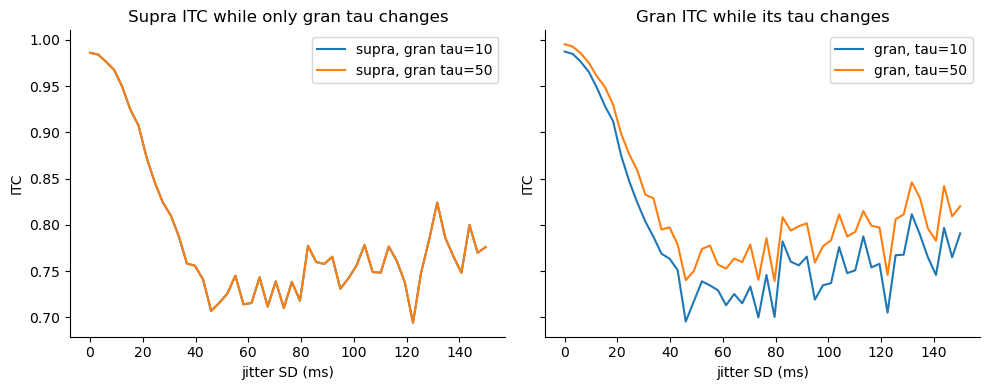

In [81]:
# Focused check: supra should not change when only gran tau_decay changes

compare_tau_sets = [
    {'supra': {'gain': 1, 'tau_decay': 10}, 'gran': {'gain': 1, 'tau_decay': 10}},
    {'supra': {'gain': 1, 'tau_decay': 10}, 'gran': {'gain': 1, 'tau_decay': 50}},
]

tau_compare = {}
for params in compare_tau_sets:
    key = params['gran']['tau_decay']
    data_case = simulate_two_layer_dataset_osc(
        fs=fs,
        dur=dur,
        f0=f0,
        jitter_sds=np.linspace(0, 0.15, 50),
        n_trials=10,
        osc_freq_hz=osc_freq_hz,
        layer_params=params,
        noise_rms=0.25,
        seed=1,
    )
    tau_compare[key] = calc_itc_for_dataset(
        data_case,
        fs=fs,
        f0=f0,
        n_cycles=5,
        sample_mode=sample_mode,
        alpha=0.05,
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for gran_tau, df_case in tau_compare.items():
    supra = df_case[df_case['layer'] == 'supra'].sort_values('jitter_sd')
    gran = df_case[df_case['layer'] == 'gran'].sort_values('jitter_sd')
    axes[0].plot(supra['jitter_sd'] * 1000, supra['ITC'], label=f'supra, gran tau={gran_tau}')
    axes[1].plot(gran['jitter_sd'] * 1000, gran['ITC'], label=f'gran, tau={gran_tau}')

axes[0].set_title('Supra ITC while only gran tau changes')
axes[0].set_xlabel('jitter SD (ms)')
axes[0].set_ylabel('ITC')
axes[1].set_title('Gran ITC while its tau changes')
axes[1].set_xlabel('jitter SD (ms)')
axes[1].set_ylabel('ITC')
for ax in axes:
    ax.legend()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

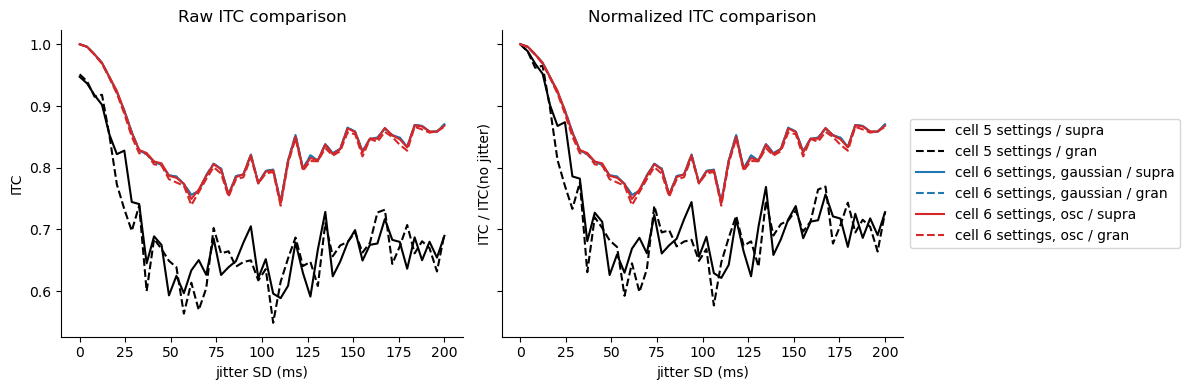

In [39]:
# Controlled comparison: cell 5 vs cell 6 assumptions

compare_fs = 500
compare_dur = 8.0
compare_f0 = 10
compare_jitter_sds = np.linspace(0, 0.2, 50)
compare_layer_gains = {'supra': 1.0, 'gran': 1.0}
compare_layer_params = {'supra': {'gain': 1.0, 'tau_decay': 2}, 'gran': {'gain': 1.0, 'tau_decay': 5}}

# 1) Gaussian pulses under cell-5-like settings

gauss_cell5 = simulate_two_layer_dataset(
    fs=compare_fs,
    dur=compare_dur,
    f0=compare_f0,
    jitter_sds=compare_jitter_sds,
    n_trials=200,
    stim_sigma_ms=2,
    layer_gains=compare_layer_gains,
    noise_rms=50.0,
    seed=1,
)

df_gauss_cell5 = calc_itc_for_dataset(
    gauss_cell5,
    fs=compare_fs,
    f0=compare_f0,
    n_cycles=5,
    sample_mode='one_per_trial',
    alpha=0.05,
)

# 2) Same Gaussian pulses under cell-6-like settings

gauss_cell6 = simulate_two_layer_dataset(
    fs=compare_fs,
    dur=compare_dur,
    f0=compare_f0,
    jitter_sds=compare_jitter_sds,
    n_trials=10,
    stim_sigma_ms=2,
    layer_gains=compare_layer_gains,
    noise_rms=0.0,
    seed=1,
)

df_gauss_cell6 = calc_itc_for_dataset(
    gauss_cell6,
    fs=compare_fs,
    f0=compare_f0,
    n_cycles=5,
    sample_mode='all_events',
    alpha=0.05,
)

# 3) Oscillatory pulses under cell-6-like settings

osc_cell6 = simulate_two_layer_dataset_osc(
    fs=compare_fs,
    dur=compare_dur,
    f0=compare_f0,
    jitter_sds=compare_jitter_sds,
    n_trials=10,
    osc_freq_hz=compare_f0,
    layer_params=compare_layer_params,
    noise_rms=0.0,
    seed=1,
)

df_osc_cell6 = calc_itc_for_dataset(
    osc_cell6,
    fs=compare_fs,
    f0=compare_f0,
    n_cycles=5,
    sample_mode='all_events',
    alpha=0.05,
)

# Summaries at max jitter and zero jitter
summary_compare = pd.DataFrame([
    {
        'case': 'gaussian_cell5_like',
        'sample_mode': 'one_per_trial',
        'noise_rms': 50.0,
        'n_trials': 200,
        'ITC0_supra': df_gauss_cell5[df_gauss_cell5['layer'] == 'supra']['ITC'].iloc[0],
        'ITCmax_supra': df_gauss_cell5[df_gauss_cell5['layer'] == 'supra']['ITC'].iloc[-1],
        'ITC0_gran': df_gauss_cell5[df_gauss_cell5['layer'] == 'gran']['ITC'].iloc[0],
        'ITCmax_gran': df_gauss_cell5[df_gauss_cell5['layer'] == 'gran']['ITC'].iloc[-1],
    },
    {
        'case': 'gaussian_cell6_like',
        'sample_mode': 'all_events',
        'noise_rms': 0.0,
        'n_trials': 10,
        'ITC0_supra': df_gauss_cell6[df_gauss_cell6['layer'] == 'supra']['ITC'].iloc[0],
        'ITCmax_supra': df_gauss_cell6[df_gauss_cell6['layer'] == 'supra']['ITC'].iloc[-1],
        'ITC0_gran': df_gauss_cell6[df_gauss_cell6['layer'] == 'gran']['ITC'].iloc[0],
        'ITCmax_gran': df_gauss_cell6[df_gauss_cell6['layer'] == 'gran']['ITC'].iloc[-1],
    },
    {
        'case': 'osc_cell6_like',
        'sample_mode': 'all_events',
        'noise_rms': 0.0,
        'n_trials': 10,
        'ITC0_supra': df_osc_cell6[df_osc_cell6['layer'] == 'supra']['ITC'].iloc[0],
        'ITCmax_supra': df_osc_cell6[df_osc_cell6['layer'] == 'supra']['ITC'].iloc[-1],
        'ITC0_gran': df_osc_cell6[df_osc_cell6['layer'] == 'gran']['ITC'].iloc[0],
        'ITCmax_gran': df_osc_cell6[df_osc_cell6['layer'] == 'gran']['ITC'].iloc[-1],
    },
])

summary_compare

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
plot_specs = [
    ('gaussian_cell5_like', df_gauss_cell5, 'cell 5 settings'),
    ('gaussian_cell6_like', df_gauss_cell6, 'cell 6 settings, gaussian'),
    ('osc_cell6_like', df_osc_cell6, 'cell 6 settings, osc'),
]
colors = {'gaussian_cell5_like': 'black', 'gaussian_cell6_like': 'tab:blue', 'osc_cell6_like': 'tab:red'}
linestyles = {'supra': '-', 'gran': '--'}

for case, df_case, label in plot_specs:
    for layer in ['supra', 'gran']:
        g = df_case[df_case['layer'] == layer].sort_values('jitter_sd')
        axes[0].plot(g['jitter_sd'] * 1000, g['ITC'], color=colors[case], linestyle=linestyles[layer], label=f'{label} / {layer}')
        axes[1].plot(g['jitter_sd'] * 1000, g['ITC_norm'], color=colors[case], linestyle=linestyles[layer], label=f'{label} / {layer}')

axes[0].set_title('Raw ITC comparison')
axes[0].set_xlabel('jitter SD (ms)')
axes[0].set_ylabel('ITC')
axes[1].set_title('Normalized ITC comparison')
axes[1].set_xlabel('jitter SD (ms)')
axes[1].set_ylabel('ITC / ITC(no jitter)')

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

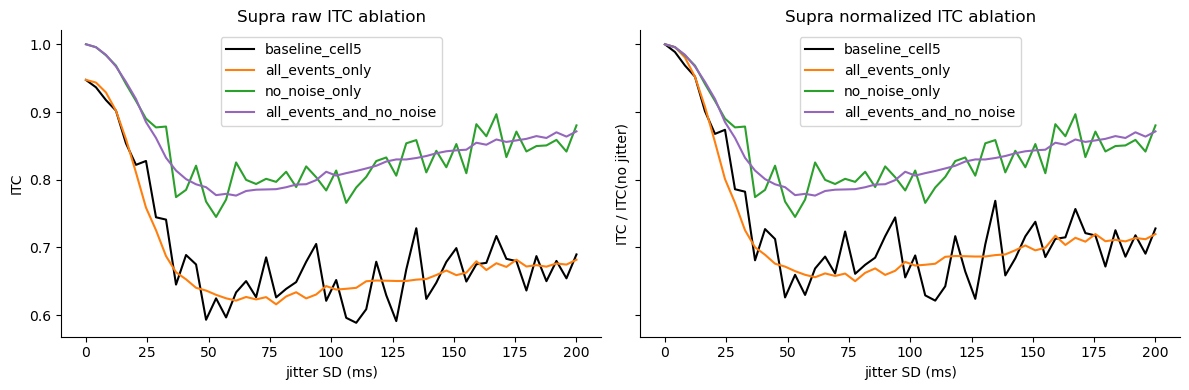

In [40]:
# Decompose the cause: sample_mode vs noise floor

ablation_cases = [
    dict(name='baseline_cell5', sample_mode='one_per_trial', noise_rms=50.0),
    dict(name='all_events_only', sample_mode='all_events', noise_rms=50.0),
    dict(name='no_noise_only', sample_mode='one_per_trial', noise_rms=0.0),
    dict(name='all_events_and_no_noise', sample_mode='all_events', noise_rms=0.0),
]

ablation = {}
for case in ablation_cases:
    data_case = simulate_two_layer_dataset(
        fs=compare_fs,
        dur=compare_dur,
        f0=compare_f0,
        jitter_sds=compare_jitter_sds,
        n_trials=200,
        stim_sigma_ms=2,
        layer_gains=compare_layer_gains,
        noise_rms=case['noise_rms'],
        seed=1,
    )
    ablation[case['name']] = calc_itc_for_dataset(
        data_case,
        fs=compare_fs,
        f0=compare_f0,
        n_cycles=5,
        sample_mode=case['sample_mode'],
        alpha=0.05,
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
colors = {
    'baseline_cell5': 'black',
    'all_events_only': 'tab:orange',
    'no_noise_only': 'tab:green',
    'all_events_and_no_noise': 'tab:purple',
}

for case in ablation_cases:
    name = case['name']
    g = ablation[name][ablation[name]['layer'] == 'supra'].sort_values('jitter_sd')
    axes[0].plot(g['jitter_sd'] * 1000, g['ITC'], color=colors[name], label=name)
    axes[1].plot(g['jitter_sd'] * 1000, g['ITC_norm'], color=colors[name], label=name)

axes[0].set_title('Supra raw ITC ablation')
axes[0].set_xlabel('jitter SD (ms)')
axes[0].set_ylabel('ITC')
axes[1].set_title('Supra normalized ITC ablation')
axes[1].set_xlabel('jitter SD (ms)')
axes[1].set_ylabel('ITC / ITC(no jitter)')
for ax in axes:
    ax.legend()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

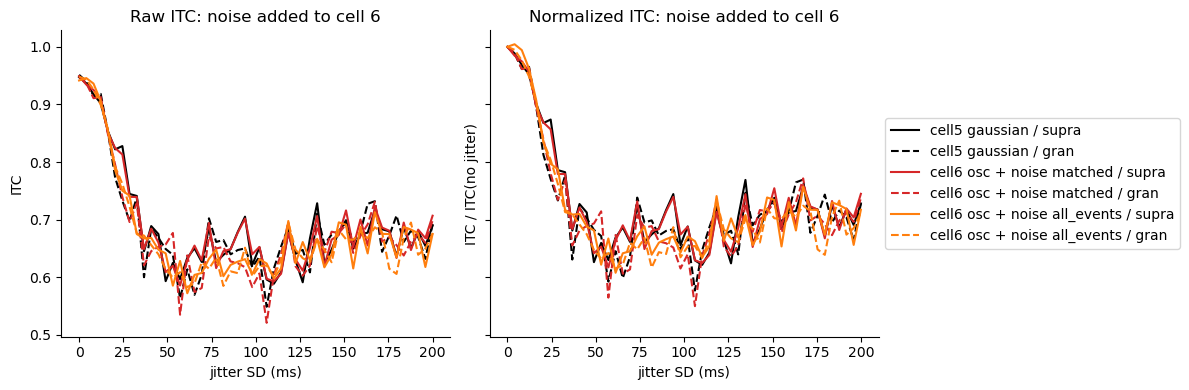

In [41]:
# Direct test: does adding noise make cell 6 match cell 5?

osc_with_noise = simulate_two_layer_dataset_osc(
    fs=compare_fs,
    dur=compare_dur,
    f0=compare_f0,
    jitter_sds=compare_jitter_sds,
    n_trials=200,
    osc_freq_hz=compare_f0,
    layer_params=compare_layer_params,
    noise_rms=50.0,
    seed=1,
)

df_osc_with_noise = calc_itc_for_dataset(
    osc_with_noise,
    fs=compare_fs,
    f0=compare_f0,
    n_cycles=5,
    sample_mode='one_per_trial',
    alpha=0.05,
)

osc_with_noise_all_events = simulate_two_layer_dataset_osc(
    fs=compare_fs,
    dur=compare_dur,
    f0=compare_f0,
    jitter_sds=compare_jitter_sds,
    n_trials=10,
    osc_freq_hz=compare_f0,
    layer_params=compare_layer_params,
    noise_rms=50.0,
    seed=1,
)

df_osc_with_noise_all_events = calc_itc_for_dataset(
    osc_with_noise_all_events,
    fs=compare_fs,
    f0=compare_f0,
    n_cycles=5,
    sample_mode='all_events',
    alpha=0.05,
)

summary_noise_match = pd.DataFrame([
    {
        'case': 'gaussian_cell5_like',
        'sample_mode': 'one_per_trial',
        'noise_rms': 50.0,
        'n_trials': 200,
        'ITC0_supra': df_gauss_cell5[df_gauss_cell5['layer'] == 'supra']['ITC'].iloc[0],
        'ITCmax_supra': df_gauss_cell5[df_gauss_cell5['layer'] == 'supra']['ITC'].iloc[-1],
        'ITC0_gran': df_gauss_cell5[df_gauss_cell5['layer'] == 'gran']['ITC'].iloc[0],
        'ITCmax_gran': df_gauss_cell5[df_gauss_cell5['layer'] == 'gran']['ITC'].iloc[-1],
    },
    {
        'case': 'osc_with_noise_matched',
        'sample_mode': 'one_per_trial',
        'noise_rms': 50.0,
        'n_trials': 200,
        'ITC0_supra': df_osc_with_noise[df_osc_with_noise['layer'] == 'supra']['ITC'].iloc[0],
        'ITCmax_supra': df_osc_with_noise[df_osc_with_noise['layer'] == 'supra']['ITC'].iloc[-1],
        'ITC0_gran': df_osc_with_noise[df_osc_with_noise['layer'] == 'gran']['ITC'].iloc[0],
        'ITCmax_gran': df_osc_with_noise[df_osc_with_noise['layer'] == 'gran']['ITC'].iloc[-1],
    },
    {
        'case': 'osc_with_noise_cell6_style',
        'sample_mode': 'all_events',
        'noise_rms': 50.0,
        'n_trials': 10,
        'ITC0_supra': df_osc_with_noise_all_events[df_osc_with_noise_all_events['layer'] == 'supra']['ITC'].iloc[0],
        'ITCmax_supra': df_osc_with_noise_all_events[df_osc_with_noise_all_events['layer'] == 'supra']['ITC'].iloc[-1],
        'ITC0_gran': df_osc_with_noise_all_events[df_osc_with_noise_all_events['layer'] == 'gran']['ITC'].iloc[0],
        'ITCmax_gran': df_osc_with_noise_all_events[df_osc_with_noise_all_events['layer'] == 'gran']['ITC'].iloc[-1],
    },
])
summary_noise_match

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
plot_specs = [
    ('cell5 gaussian', df_gauss_cell5, 'black'),
    ('cell6 osc + noise matched', df_osc_with_noise, 'tab:red'),
    ('cell6 osc + noise all_events', df_osc_with_noise_all_events, 'tab:orange'),
]
linestyles = {'supra': '-', 'gran': '--'}

for label, df_case, color in plot_specs:
    for layer in ['supra', 'gran']:
        g = df_case[df_case['layer'] == layer].sort_values('jitter_sd')
        axes[0].plot(g['jitter_sd'] * 1000, g['ITC'], color=color, linestyle=linestyles[layer], label=f'{label} / {layer}')
        axes[1].plot(g['jitter_sd'] * 1000, g['ITC_norm'], color=color, linestyle=linestyles[layer], label=f'{label} / {layer}')

axes[0].set_title('Raw ITC: noise added to cell 6')
axes[0].set_xlabel('jitter SD (ms)')
axes[0].set_ylabel('ITC')
axes[1].set_title('Normalized ITC: noise added to cell 6')
axes[1].set_xlabel('jitter SD (ms)')
axes[1].set_ylabel('ITC / ITC(no jitter)')

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[1].legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()